In [1]:
import pandas as pd
import json
import os

print("working dir:", os.getcwd())

working dir: E:\ETA-HACKATHON


In [2]:
# loading the raw files
delay_df = pd.read_csv("indian_railway_delay_data_.csv")
train_df = pd.read_csv("Train_details_22122017.csv")

with open("schedules.json", "r", encoding="utf-8") as f:
    schedules = json.load(f)

with open("stations.json", "r", encoding="utf-8") as f:
    stations = json.load(f)

with open("trains.json", "r", encoding="utf-8") as f:
    trains = json.load(f)

print("all files loaded")

C:\Users\hp\AppData\Local\Temp\ipykernel_29284\1722113318.py:3: DtypeWarning: Columns (0,2,7) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv("Train_details_22122017.csv")


all files loaded


In [3]:
print("delay dataset shape:", delay_df.shape)
print("train details shape:", train_df.shape)

print("\ndelay dataset columns:")
print(delay_df.columns.tolist())

print("\ntrain details columns:")
print(train_df.columns.tolist())

print("\nschedules type:", type(schedules))
print("stations type:", type(stations))
print("trains type:", type(trains))

delay dataset shape: (100, 12)
train details shape: (186124, 12)

delay dataset columns:
['Train_id', 'Train_name', 'Train_no', 'Source', 'Destitnation', 'Date', 'Distance(Km)', 'Sc_arr__time', 'Act_arr_time', 'Dealy_min', 'Season', 'Run_frequency']

train details columns:
['Train No', 'Train Name', 'SEQ', 'Station Code', 'Station Name', 'Arrival time', 'Departure Time', 'Distance', 'Source Station', 'Source Station Name', 'Destination Station', 'Destination Station Name']

schedules type: <class 'list'>
stations type: <class 'dict'>
trains type: <class 'dict'>


In [4]:
print("--- delay data sample ---")
display(delay_df.head())

print("--- train details sample ---")
display(train_df.head())

print("--- schedules sample ---")
print(str(schedules)[:1000])

print("--- stations sample ---")
print(str(stations)[:1000])

print("--- trains sample ---")
print(str(trains)[:1000])

--- delay data sample ---


,Train_id,Train_name,Train_no,Source,Destitnation,Date,Distance(Km),Sc_arr__time,Act_arr_time,Dealy_min,Season,Run_frequency
0,E1,Begampura Express,12238,Varanasi,Jammu,01-01-2016 00:00,1260,06:30:00,07:45:00,01:15:00,Winter,Daliy
1,E2,Begampura Express,12238,Varanasi,Jammu,01-01-2017 00:00,1260,06:30:00,06:50:00,00:20:00,Winter,Daliy
2,E3,Begampura Express,12238,Varanasi,Jammu,01-01-2018 00:00,1260,06:30:00,08:00:00,01:30:00,Winter,Daliy
3,E4,Begampura Express,12238,Varanasi,Jammu,01-01-2019 00:00,1260,06:30:00,06:40:00,00:10:00,Winter,Daliy
4,E5,Begampura Express,12238,Varanasi,Jammu,01-01-2020 00:00,1260,06:30:00,07:00:00,00:30:00,Winter,Daliy


--- train details sample ---


,Train No,Train Name,SEQ,Station Code,Station Name,Arrival time,Departure Time,Distance,Source Station,Source Station Name,Destination Station,Destination Station Name
0,107,SWV-MAO-VLNK,1,SWV,SAWANTWADI R,00:00:00,10:25:00,0,SWV,SAWANTWADI ROAD,MAO,MADGOAN JN.
1,107,SWV-MAO-VLNK,2,THVM,THIVIM,11:06:00,11:08:00,32,SWV,SAWANTWADI ROAD,MAO,MADGOAN JN.
2,107,SWV-MAO-VLNK,3,KRMI,KARMALI,11:28:00,11:30:00,49,SWV,SAWANTWADI ROAD,MAO,MADGOAN JN.
3,107,SWV-MAO-VLNK,4,MAO,MADGOAN JN.,12:10:00,00:00:00,78,SWV,SAWANTWADI ROAD,MAO,MADGOAN JN.
4,108,VLNK-MAO-SWV,1,MAO,MADGOAN JN.,00:00:00,20:30:00,0,MAO,MADGOAN JN.,SWV,SAWANTWADI ROAD


--- schedules sample ---
[{'arrival': 'None', 'day': 1, 'train_name': 'Falaknuma Lingampalli MMTS', 'station_name': 'KACHEGUDA FALAKNUMA', 'station_code': 'FM', 'id': 302214, 'train_number': '47154', 'departure': '07:55:00'}, {'arrival': 'None', 'day': 1, 'train_name': 'Thrissur Guruvayur Passenger', 'station_name': 'THRISUR', 'station_code': 'TCR', 'id': 281458, 'train_number': '56044', 'departure': '18:55:00'}, {'arrival': 'None', 'day': 1, 'train_name': 'Porbandar Muzaffarpur Express', 'station_name': 'PORBANDAR', 'station_code': 'PBR', 'id': 309335, 'train_number': '19269', 'departure': '15:05:00'}, {'arrival': 'None', 'day': 1, 'train_name': 'RAIPUR ITWARI PASS', 'station_name': 'RAIPUR JN', 'station_code': 'R', 'id': 283774, 'train_number': '58205', 'departure': '13:30:00'}, {'arrival': 'None', 'day': 1, 'train_name': 'Gomoh-Asansol MEMU', 'station_name': 'GOMOH JN', 'station_code': 'GMO', 'id': 319937, 'train_number': '63542', 'departure': '07:20:00'}, {'arrival': 'None', 'day':

In [5]:
# schedules is already a list of dicts so it converts directly
schedule_df = pd.DataFrame(schedules)

# trains and stations are geojson, so pull out the properties
train_sections_df = pd.DataFrame([
    feature["properties"]
    for feature in trains["features"]
])

stations_df = pd.DataFrame([
    feature["properties"]
    for feature in stations["features"]
])

print("schedule df:", schedule_df.shape)
print("train sections df:", train_sections_df.shape)
print("stations df:", stations_df.shape)

display(schedule_df.head())
display(train_sections_df.head())
display(stations_df.head())

schedule df: (417080, 8)
train sections df: (5208, 21)
stations df: (8990, 5)


,arrival,day,train_name,station_name,station_code,id,train_number,departure
0,None,1.0,Falaknuma Lingampalli MMTS,KACHEGUDA FALAKNUMA,FM,302214,47154,07:55:00
1,None,1.0,Thrissur Guruvayur Passenger,THRISUR,TCR,281458,56044,18:55:00
2,None,1.0,Porbandar Muzaffarpur Express,PORBANDAR,PBR,309335,19269,15:05:00
3,None,1.0,RAIPUR ITWARI PASS,RAIPUR JN,R,283774,58205,13:30:00
4,None,1.0,Gomoh-Asansol MEMU,GOMOH JN,GMO,319937,63542,07:20:00


,third_ac,arrival,from_station_code,name,zone,chair_car,first_class,duration_m,sleeper,from_station_name,...,departure,return_train,to_station_code,second_ac,classes,to_station_name,duration_h,type,first_ac,distance
0,0,12:15:00,JAT,Jammu Tawi Udhampur Special,NR,0,0,35.0,0,JAMMU TAWI,...,10:40:00,04602,UHP,0,,UDHAMPUR,1.0,DEMU,0,53.0
1,0,08:35:00,UHP,UDHAMPUR JAMMUTAWI DMU,NR,0,0,50.0,0,UDHAMPUR,...,06:45:00,04601,JAT,0,,JAMMU TAWI,1.0,DEMU,0,53.0
2,0,17:50:00,JAT,JAT UDAHMPUR DMU,NR,0,0,35.0,0,JAMMU TAWI,...,16:15:00,04604,UHP,0,,UDHAMPUR,1.0,DEMU,0,53.0
3,0,19:50:00,UHP,UDHAMPUR JAMMUTAWI DMU,NR,0,0,30.0,0,UDHAMPUR,...,18:20:00,04603,JAT,0,,JAMMU TAWI,1.0,DEMU,0,53.0
4,1,12:30:00,BDTS,Mumbai BandraT-Bikaner SF Special,NWR,0,0,55.0,1,MUMBAI BANDRA TERMINUS,...,14:35:00,04727,BKN,1,,BIKANER JN,21.0,SF,0,1212.0


,state,code,name,zone,address
0,Rajasthan,BDHL,Badhal,NWR,"Kishangarh Renwal, Rajasthan"
1,None,XX-BECE,XX-BECE,None,None
2,None,XX-BSPY,XX-BSPY,None,None
3,None,YY-BPLC,YY-BPLC,None,None
4,Uttar Pradesh,KHH,KICHHA,NER,"Kichha, Uttar Pradesh"


In [6]:
# match train numbers between the delay dataset and the route dataset
delay_trains = set(delay_df["Train_no"].astype(str).str.strip())
route_trains = set(train_df["Train No"].astype(str).str.strip())

common_trains = delay_trains.intersection(route_trains)

print("delay dataset unique trains:", len(delay_trains))
print("route dataset unique trains:", len(route_trains))
print("common train numbers:", len(common_trains))
print(list(common_trains)[:20])

delay dataset unique trains: 10
route dataset unique trains: 11113
common train numbers: 10
['12301', '12633', '12229', '22832', '15029', '12377', '15906', '12002', '12604', '12238']


In [7]:
# train number columns clean aur numeric format me
delay_df["Train_no"] = delay_df["Train_no"].astype(str).str.strip()
train_df["Train No"] = train_df["Train No"].astype(str).str.strip()

# sirf un trains ka route data rakho jo delay dataset me hain
common_route_df = train_df[train_df["Train No"].isin(common_trains)].copy()

print("common route records:", common_route_df.shape)
display(common_route_df.head(10))

common route records: (185, 12)


,Train No,Train Name,SEQ,Station Code,Station Name,Arrival time,Departure Time,Distance,Source Station,Source Station Name,Destination Station,Destination Station Name
8536,12002,NDLS - BPL S,1,NDLS,NEW DELHI,06:00:00,06:00:00,0,NDLS,NEW DELHI,HBJ,HABIBGANJ
8537,12002,NDLS - BPL S,2,MTJ,MATHURA JN.,07:23:00,07:24:00,137,NDLS,NEW DELHI,HBJ,HABIBGANJ
8538,12002,NDLS - BPL S,3,AGC,AGRA CANTT,07:57:00,08:02:00,191,NDLS,NEW DELHI,HBJ,HABIBGANJ
8539,12002,NDLS - BPL S,4,DHO,DHAULPUR,08:41:00,08:42:00,243,NDLS,NEW DELHI,HBJ,HABIBGANJ
8540,12002,NDLS - BPL S,5,MRA,MORENA,09:01:00,09:02:00,259,NDLS,NEW DELHI,HBJ,HABIBGANJ
8541,12002,NDLS - BPL S,6,GWL,GWALIOR JN,09:28:00,09:33:00,298,NDLS,NEW DELHI,HBJ,HABIBGANJ
8542,12002,NDLS - BPL S,7,JHS,JHANSI JN,10:43:00,10:51:00,395,NDLS,NEW DELHI,HBJ,HABIBGANJ
8543,12002,NDLS - BPL S,8,LAR,LALITPUR,11:39:00,11:41:00,483,NDLS,NEW DELHI,HBJ,HABIBGANJ
8544,12002,NDLS - BPL S,9,BPL,BHOPAL,13:50:00,13:55:00,684,NDLS,NEW DELHI,HBJ,HABIBGANJ
8545,12002,NDLS - BPL S,10,HBJ,HABIBGANJ,14:25:00,14:25:00,690,NDLS,NEW DELHI,HBJ,HABIBGANJ


In [8]:
common_route_df = common_route_df.drop(
    columns=["Total_Distance", "Remaining_Distance"],
    errors="ignore"
)

common_route_df["Distance"] = pd.to_numeric(
    common_route_df["Distance"].astype(str).str.strip(),
    errors="coerce"
).astype("float64")

print("Distance dtype:", common_route_df["Distance"].dtype)
print("missing distance values:", common_route_df["Distance"].isna().sum())

# total distance per train, then how much is left at each stop
common_route_df["Total_Distance"] = (
    common_route_df.groupby("Train No")["Distance"].transform("max").astype("float64")
)
common_route_df["Remaining_Distance"] = (
    common_route_df["Total_Distance"].to_numpy() - common_route_df["Distance"].to_numpy()
)

display(common_route_df[[
    "Train No", "SEQ", "Station Code", "Station Name",
    "Distance", "Total_Distance", "Remaining_Distance"
]].head(15))

Distance dtype: float64
missing distance values: 0


,Train No,SEQ,Station Code,Station Name,Distance,Total_Distance,Remaining_Distance
8536,12002,1,NDLS,NEW DELHI,0.0,690.0,690.0
8537,12002,2,MTJ,MATHURA JN.,137.0,690.0,553.0
8538,12002,3,AGC,AGRA CANTT,191.0,690.0,499.0
8539,12002,4,DHO,DHAULPUR,243.0,690.0,447.0
8540,12002,5,MRA,MORENA,259.0,690.0,431.0
8541,12002,6,GWL,GWALIOR JN,298.0,690.0,392.0
8542,12002,7,JHS,JHANSI JN,395.0,690.0,295.0
8543,12002,8,LAR,LALITPUR,483.0,690.0,207.0
8544,12002,9,BPL,BHOPAL,684.0,690.0,6.0
8545,12002,10,HBJ,HABIBGANJ,690.0,690.0,0.0


## scheduled remaining time

In [9]:
common_route_df["SEQ"] = pd.to_numeric(common_route_df["SEQ"], errors="coerce")

common_route_df = common_route_df.sort_values(["Train No", "SEQ"]).copy()

arrival_dt = pd.to_datetime(
    common_route_df["Arrival time"].astype(str).str.strip(),
    format="%H:%M:%S",
    errors="coerce"
)
common_route_df["Arrival_Minutes"] = arrival_dt.dt.hour * 60 + arrival_dt.dt.minute

# arrival time resets after midnight, so track day rollovers per train
common_route_df["Day_Offset"] = (
    common_route_df.groupby("Train No")["Arrival_Minutes"]
    .transform(lambda x: x.diff().lt(0).cumsum())
)
common_route_df["Continuous_Arrival_Minutes"] = (
    common_route_df["Arrival_Minutes"] + common_route_df["Day_Offset"] * 1440
)

common_route_df["Destination_Continuous_Minutes"] = (
    common_route_df.groupby("Train No")["Continuous_Arrival_Minutes"].transform("max")
)
common_route_df["Scheduled_Remaining_Minutes"] = (
    common_route_df["Destination_Continuous_Minutes"] - common_route_df["Continuous_Arrival_Minutes"]
)

print("arrival time missing:", common_route_df["Arrival_Minutes"].isna().sum())

display(common_route_df[[
    "Train No", "SEQ", "Station Name", "Arrival time",
    "Remaining_Distance", "Scheduled_Remaining_Minutes"
]].head(20))

arrival time missing: 0


,Train No,SEQ,Station Name,Arrival time,Remaining_Distance,Scheduled_Remaining_Minutes
8536,12002,1,NEW DELHI,06:00:00,690.0,505
8537,12002,2,MATHURA JN.,07:23:00,553.0,422
8538,12002,3,AGRA CANTT,07:57:00,499.0,388
8539,12002,4,DHAULPUR,08:41:00,447.0,344
8540,12002,5,MORENA,09:01:00,431.0,324
8541,12002,6,GWALIOR JN,09:28:00,392.0,297
8542,12002,7,JHANSI JN,10:43:00,295.0,222
8543,12002,8,LALITPUR,11:39:00,207.0,166
8544,12002,9,BHOPAL,13:50:00,6.0,35
8545,12002,10,HABIBGANJ,14:25:00,0.0,0


## inspect delay dataset

In [10]:
delay_time = pd.to_timedelta(
    delay_df["Dealy_min"].astype(str).str.strip(),
    errors="coerce"
)
delay_df["Delay_Minutes"] = delay_time.dt.total_seconds() / 60

print("missing delay values:", delay_df["Delay_Minutes"].isna().sum())
print(delay_df["Delay_Minutes"].describe())

display(delay_df[["Train_no", "Train_name", "Date", "Dealy_min", "Delay_Minutes"]].head(10))

missing delay values: 1
count     99.000000
mean      36.666667
std       38.370907
min        0.000000
25%       10.000000
50%       25.000000
75%       50.000000
max      244.000000
Name: Delay_Minutes, dtype: float64


,Train_no,Train_name,Date,Dealy_min,Delay_Minutes
0,12238,Begampura Express,01-01-2016 00:00,01:15:00,75.0
1,12238,Begampura Express,01-01-2017 00:00,00:20:00,20.0
2,12238,Begampura Express,01-01-2018 00:00,01:30:00,90.0
3,12238,Begampura Express,01-01-2019 00:00,00:10:00,10.0
4,12238,Begampura Express,01-01-2020 00:00,00:30:00,30.0
5,12238,Begampura Express,07-01-2021 00:00,00:05:00,5.0
6,12238,Begampura Express,01-01-2022 00:00,00:40:00,40.0
7,12238,Begampura Express,01-01-2023 00:00,01:30:00,90.0
8,12238,Begampura Express,01-01-2024 00:00,00:15:00,15.0
9,12238,Begampura Express,01-01-2025 00:00,00:50:00,50.0


In [11]:
missing_delay_rows = delay_df[delay_df["Delay_Minutes"].isna()]
print("missing delay records:", len(missing_delay_rows))
display(missing_delay_rows)

missing delay records: 1


,Train_id,Train_name,Train_no,Source,Destitnation,Date,Distance(Km),Sc_arr__time,Act_arr_time,Dealy_min,Season,Run_frequency,Delay_Minutes
83,Y4,Yesvantpur–Howrah Express,22832,Yesvantpur Jn,Howrah,01-01-2019 00:00,1915,04:30:00,04:50:00,20-01-1900 00:20,Winter,Daliy,NaN


In [12]:
# a couple of rows had a full date-time string instead of just the delay duration
print(delay_df.loc[delay_df["Delay_Minutes"].isna(), "Dealy_min"])

delay_df["Dealy_min"] = (
    delay_df["Dealy_min"].astype(str).str.extract(r"(\d{2}:\d{2}(?::\d{2})?)")[0]
)

delay_time = pd.to_timedelta(delay_df["Dealy_min"], errors="coerce")
delay_df["Delay_Minutes"] = delay_time.dt.total_seconds() / 60

print("missing after fix:", delay_df["Delay_Minutes"].isna().sum())

display(delay_df.loc[delay_df["Train_id"] == "Y4", ["Train_id", "Dealy_min", "Delay_Minutes"]])

83    20-01-1900 00:20
Name: Dealy_min, dtype: object
missing after fix: 1


,Train_id,Dealy_min,Delay_Minutes
83,Y4,00:20,NaN


In [13]:
# to_timedelta still choked on one format, so parsing it manually
delay_parts = (
    delay_df["Dealy_min"].astype(str).str.extract(r"(?:(\d{2}):)?(\d{2})(?::(\d{2}))?$")
)

hours = pd.to_numeric(delay_parts[0], errors="coerce").fillna(0)
minutes = pd.to_numeric(delay_parts[1], errors="coerce").fillna(0)
seconds = pd.to_numeric(delay_parts[2], errors="coerce").fillna(0)

delay_df["Delay_Minutes"] = hours * 60 + minutes + seconds / 60

print("missing after manual fix:", delay_df["Delay_Minutes"].isna().sum())

display(delay_df.loc[delay_df["Train_id"] == "Y4", ["Train_id", "Dealy_min", "Delay_Minutes"]])

missing after manual fix: 0


,Train_id,Dealy_min,Delay_Minutes
83,Y4,00:20,20.0


In [14]:
delay_df["Train_no"] = delay_df["Train_no"].astype(str).str.strip()

historical_delay_df = (
    delay_df.groupby("Train_no")["Delay_Minutes"]
    .agg(
        Historical_Avg_Delay="mean",
        Historical_Max_Delay="max",
        Historical_Min_Delay="min",
        Historical_Record_Count="count"
    )
    .reset_index()
)

historical_delay_df[["Historical_Avg_Delay", "Historical_Max_Delay", "Historical_Min_Delay"]] = (
    historical_delay_df[["Historical_Avg_Delay", "Historical_Max_Delay", "Historical_Min_Delay"]].round(2)
)

display(historical_delay_df)

,Train_no,Historical_Avg_Delay,Historical_Max_Delay,Historical_Min_Delay,Historical_Record_Count
0,12002,38.9,130.0,5.0,10
1,12229,25.5,70.0,1.0,10
2,12238,42.5,90.0,5.0,10
3,12301,38.5,75.0,5.0,10
4,12377,27.4,100.0,0.0,10
5,12604,37.5,75.0,5.0,10
6,12633,27.2,65.0,0.0,10
7,15029,48.5,120.0,10.0,10
8,15906,20.4,63.0,0.0,10
9,22832,58.6,244.0,0.0,10


In [15]:
common_route_df["Train No"] = common_route_df["Train No"].astype(str).str.strip()
historical_delay_df["Train_no"] = historical_delay_df["Train_no"].astype(str).str.strip()

ml_df = common_route_df.merge(
    historical_delay_df,
    left_on="Train No",
    right_on="Train_no",
    how="left"
)

print("route records:", len(common_route_df))
print("ml dataset records:", len(ml_df))
print("missing historical delay values:", ml_df["Historical_Avg_Delay"].isna().sum())

display(ml_df[[
    "Train No", "SEQ", "Station Name", "Remaining_Distance",
    "Scheduled_Remaining_Minutes", "Historical_Avg_Delay",
    "Historical_Max_Delay", "Historical_Min_Delay", "Historical_Record_Count"
]].head(15))

route records: 185
ml dataset records: 185
missing historical delay values: 0


,Train No,SEQ,Station Name,Remaining_Distance,Scheduled_Remaining_Minutes,Historical_Avg_Delay,Historical_Max_Delay,Historical_Min_Delay,Historical_Record_Count
0,12002,1,NEW DELHI,690.0,505,38.9,130.0,5.0,10
1,12002,2,MATHURA JN.,553.0,422,38.9,130.0,5.0,10
2,12002,3,AGRA CANTT,499.0,388,38.9,130.0,5.0,10
3,12002,4,DHAULPUR,447.0,344,38.9,130.0,5.0,10
4,12002,5,MORENA,431.0,324,38.9,130.0,5.0,10
5,12002,6,GWALIOR JN,392.0,297,38.9,130.0,5.0,10
6,12002,7,JHANSI JN,295.0,222,38.9,130.0,5.0,10
7,12002,8,LALITPUR,207.0,166,38.9,130.0,5.0,10
8,12002,9,BHOPAL,6.0,35,38.9,130.0,5.0,10
9,12002,10,HABIBGANJ,0.0,0,38.9,130.0,5.0,10


In [16]:
# eta = however much time is scheduled to be left + the train's usual delay
ml_df["Expected_ETA_Minutes"] = (
    ml_df["Scheduled_Remaining_Minutes"] + ml_df["Historical_Avg_Delay"]
).round(2)

display(ml_df[[
    "Train No", "SEQ", "Station Name", "Remaining_Distance",
    "Scheduled_Remaining_Minutes", "Historical_Avg_Delay", "Expected_ETA_Minutes"
]].head(15))

print(ml_df["Expected_ETA_Minutes"].describe())

,Train No,SEQ,Station Name,Remaining_Distance,Scheduled_Remaining_Minutes,Historical_Avg_Delay,Expected_ETA_Minutes
0,12002,1,NEW DELHI,690.0,505,38.9,543.9
1,12002,2,MATHURA JN.,553.0,422,38.9,460.9
2,12002,3,AGRA CANTT,499.0,388,38.9,426.9
3,12002,4,DHAULPUR,447.0,344,38.9,382.9
4,12002,5,MORENA,431.0,324,38.9,362.9
5,12002,6,GWALIOR JN,392.0,297,38.9,335.9
6,12002,7,JHANSI JN,295.0,222,38.9,260.9
7,12002,8,LALITPUR,207.0,166,38.9,204.9
8,12002,9,BHOPAL,6.0,35,38.9,73.9
9,12002,10,HABIBGANJ,0.0,0,38.9,38.9


count     185.000000
mean     1223.002703
std      1212.084346
min        20.400000
25%       356.500000
50%       724.200000
75%      1785.600000
max      4985.400000
Name: Expected_ETA_Minutes, dtype: float64


In [17]:
feature_columns = [
    "SEQ",
    "Remaining_Distance",
    "Scheduled_Remaining_Minutes",
    "Historical_Avg_Delay",
    "Historical_Max_Delay",
    "Historical_Min_Delay"
]
target_column = "Expected_ETA_Minutes"

X = ml_df[feature_columns].copy()
y = ml_df[target_column].copy()

for col in feature_columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

print("X:", X.shape, " y:", y.shape)
print(X.isna().sum())
print(y.isna().sum())

display(X.head())

X: (185, 6)  y: (185,)
SEQ                            0
Remaining_Distance             0
Scheduled_Remaining_Minutes    0
Historical_Avg_Delay           0
Historical_Max_Delay           0
Historical_Min_Delay           0
dtype: int64
0


,SEQ,Remaining_Distance,Scheduled_Remaining_Minutes,Historical_Avg_Delay,Historical_Max_Delay,Historical_Min_Delay
0,1,690.0,505,38.9,130.0,5.0
1,2,553.0,422,38.9,130.0,5.0
2,3,499.0,388,38.9,130.0,5.0
3,4,447.0,344,38.9,130.0,5.0
4,5,431.0,324,38.9,130.0,5.0


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("train:", X_train.shape, "test:", X_test.shape)

train: (148, 6) test: (37, 6)


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("scaled train:", X_train_scaled.shape, "scaled test:", X_test_scaled.shape)

scaled train: (148, 6) scaled test: (37, 6)


In [20]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=200, random_state=42)
rf_model.fit(X_train_scaled, y_train)

y_pred_rf = rf_model.predict(X_test_scaled)
print(y_pred_rf[:10])

[1415.8435  662.4095  631.1605 4711.115  1284.061   261.305   895.204
  185.24   4123.805  1250.5255]


In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_rf)
mse = mean_squared_error(y_test, y_pred_rf)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_rf)

print("Random Forest performance")
print("MAE:", round(mae, 2), "minutes")
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2), "minutes")
print("R2:", round(r2, 4))

Random Forest performance
MAE: 15.16 minutes
MSE: 409.57
RMSE: 20.24 minutes
R2: 0.9998


In [22]:
comparison_df = pd.DataFrame({
    "Actual_ETA_Minutes": y_test.values,
    "Predicted_ETA_Minutes": y_pred_rf,
    "Absolute_Error": np.abs(y_test.values - y_pred_rf)
})

display(comparison_df.head(15))

,Actual_ETA_Minutes,Predicted_ETA_Minutes,Absolute_Error
0,1402.5,1415.8435,13.3435
1,652.4,662.4095,10.0095
2,620.4,631.1605,10.7605
3,4692.4,4711.1150,18.7150
4,1312.4,1284.0610,28.3390
5,245.5,261.3050,15.8050
6,907.5,895.2040,12.2960
7,169.5,185.2400,15.7400
8,4113.4,4123.8050,10.4050
9,1308.5,1250.5255,57.9745


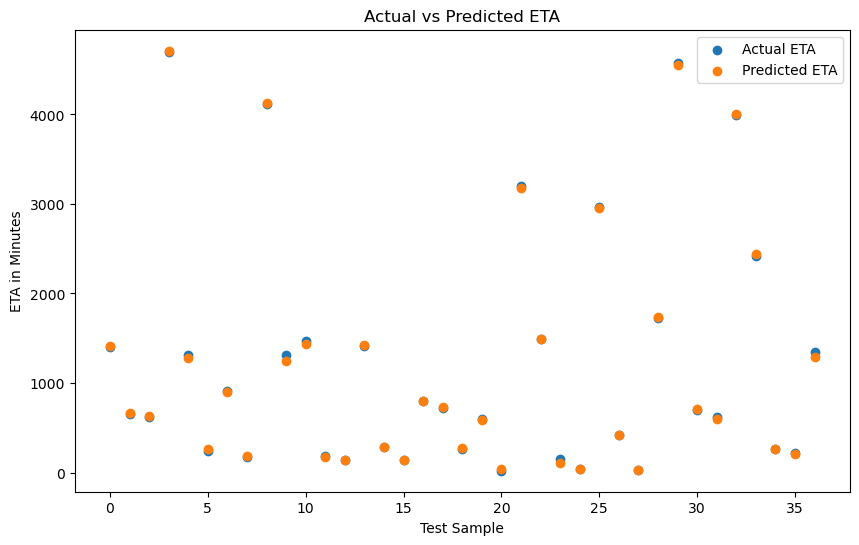

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(range(len(y_test)), y_test, label="Actual ETA")
plt.scatter(range(len(y_pred_rf)), y_pred_rf, label="Predicted ETA")
plt.xlabel("Test Sample")
plt.ylabel("ETA in Minutes")
plt.title("Actual vs Predicted ETA")
plt.legend()
plt.show()

In [24]:
def predict_eta(train_no, station_name):
    train_no = str(train_no)

    selected_row = ml_df[
        (ml_df["Train No"].astype(str) == train_no) &
        (ml_df["Station Name"].str.upper() == station_name.upper())
    ]

    if selected_row.empty:
        return {"predictedEtaMinutes": None}

    selected_row = selected_row.iloc[0]

    input_data = pd.DataFrame([[
        selected_row["SEQ"],
        selected_row["Remaining_Distance"],
        selected_row["Scheduled_Remaining_Minutes"],
        selected_row["Historical_Avg_Delay"],
        selected_row["Historical_Max_Delay"],
        selected_row["Historical_Min_Delay"]
    ]], columns=feature_columns)

    input_scaled = scaler.transform(input_data)
    predicted_eta = rf_model.predict(input_scaled)[0]

    return {"predictedEtaMinutes": round(float(predicted_eta), 2)}

In [25]:
predict_eta("12002", "BHOPAL")

{'predictedEtaMinutes': 65.73}

,Feature,Importance
2,Scheduled_Remaining_Minutes,0.868455
1,Remaining_Distance,0.121741
0,SEQ,0.009651
4,Historical_Max_Delay,0.000055
3,Historical_Avg_Delay,0.000051
5,Historical_Min_Delay,0.000047


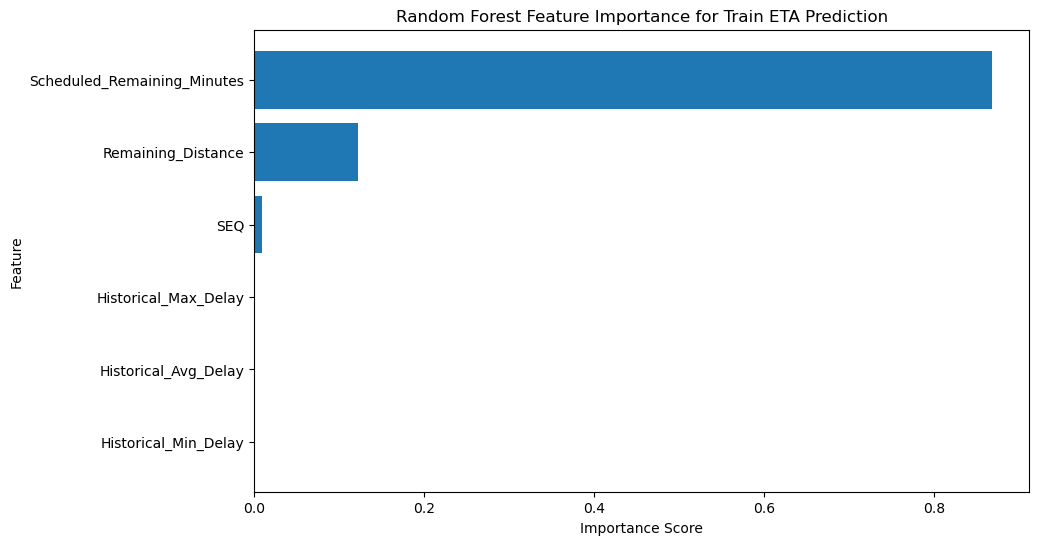

In [26]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(10, 6))
plt.barh(feature_importance["Feature"], feature_importance["Importance"])
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance for Train ETA Prediction")
plt.gca().invert_yaxis()
plt.show()

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
linear_predictions = linear_model.predict(X_test_scaled)

dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train_scaled, y_train)
dt_predictions = dt_model.predict(X_test_scaled)

rf_predictions = rf_model.predict(X_test_scaled)

model_results = []
for name, preds in [
    ("Linear Regression", linear_predictions),
    ("Decision Tree", dt_predictions),
    ("Random Forest", rf_predictions),
]:
    model_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, preds),
        "MSE": mean_squared_error(y_test, preds),
        "RMSE": np.sqrt(mean_squared_error(y_test, preds)),
        "R2 Score": r2_score(y_test, preds)
    })

comparison_df = pd.DataFrame(model_results).round(4)
display(comparison_df)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.0000,0.0000,0.0000,1.0000
1,Decision Tree,31.3595,2089.3559,45.7095,0.9988
2,Random Forest,15.1592,409.5677,20.2378,0.9998


In [28]:
# FORMAT ETA

def format_eta(minutes):
    # Convert prediction to total whole minutes
    total_minutes = round(float(minutes))

    # Calculate hours and remaining minutes
    hours = total_minutes // 60
    remaining_minutes = total_minutes % 60

    # Return a user-friendly format
    if hours > 0:
        return f"{hours} hr {remaining_minutes} min"
    else:
        return f"{remaining_minutes} min"

In [29]:
import joblib

joblib.dump(rf_model, "random_forest_eta_model.pkl")
ml_df.to_pickle("eta_ml_dataset.pkl")
joblib.dump(scaler, "eta_feature_scaler.pkl")
joblib.dump(feature_columns, "eta_feature_columns.pkl")

print("Model, ML dataset, scaler and feature list saved successfully.")

Model, ML dataset, scaler and feature list saved successfully.
